# Descripcipción del proyecto

Film Junky Union, una nueva comunidad vanguardista para los aficionados de las películas clásicas, está desarrollando un sistema para filtrar y categorizar reseñas de películas. Tu objetivo es entrenar un modelo para detectar las críticas negativas de forma automática. Para lograrlo, utilizarás un conjunto de datos de reseñas de películas de IMDB con leyendas de polaridad para construir un modelo para clasificar las reseñas positivas y negativas. Este deberá alcanzar un valor F1 de al menos 0.85.

## Introducción al proyecto: Clasificador de reseñas IMDB Film Junky Union

## Descripción del problema:
Film Junky Union, una comunidad para aficionados al cine clásico, necesita un sistema automatizado para filtrar y categorizar reseñas de películas. El objetivo principal es detectar automáticamente las críticas negativas.

## Objetivo del proyecto:
Entrenar un modelo de clasificación para identificar reseñas de películas negativas con una alta precisión.

## Métricas de evaluación:
El modelo debe alcanzar un valor F1 de al menos 0.85.

## Datos disponibles:
Los datos se almacenan en el archivo `imdb_reviews.tsv`.

Aquí se describen los campos seleccionados:

- `review`: el texto de la reseña
- `pos`: el objetivo, '0' para negativo y '1' para positivo
- `ds_part`: 'entrenamiento'/'prueba' para la parte de entrenamiento/prueba del conjunto de datos, respectivamente.

Hay otros campos en el conjunto de datos que exploraremos al cargar el data set.
## Metodología:
1.  **Carga de datos:** Importar el conjunto de datos `imdb_reviews.tsv`.
2.  **Preprocesamiento de datos:** Realizar la limpieza y normalización de los textos de las reseñas, incluyendo la conversión a minúsculas y la eliminación de dígitos y puntuación.
3.  **Análisis exploratorio de datos (EDA):** Examinar la distribución de las reseñas, el equilibrio de clases y otras características relevantes.
4.  **División de datos:** Utilizar la columna `ds_part` para separar los conjuntos de entrenamiento y prueba.
5.  **Vectorización de texto:** Transformar las reseñas de texto en representaciones numéricas (ej. TF-IDF).
6.  **Entrenamiento de modelos:** Entrenar al menos tres modelos de clasificación diferentes (ej. regresión logística, LGBMClassifier).
7.  **Evaluación de modelos:** Evaluar el rendimiento de cada modelo utilizando métricas como F1-score, ROC AUC y Average Precision Score en los conjuntos de entrenamiento y prueba. Se requiere un F1-score mínimo de 0.85.
8.  **Clasificación de nuevas reseñas:** Probar los modelos con reseñas personalizadas para analizar su comportamiento en nuevos datos.

### Inicialización

In [1]:
import math

import numpy as np
import pandas as pd

import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

from tqdm.auto import tqdm

In [2]:
%matplotlib inline
%config InlineBackend.figure_format = 'png'
# la siguiente línea proporciona gráficos de mejor calidad en pantallas HiDPI
# %config InlineBackend.figure_format = 'retina'

plt.style.use('seaborn')

In [3]:
# esto es para usar progress_apply, puedes leer más en https://pypi.org/project/tqdm/#pandas-integration
tqdm.pandas()

### Cargar datos

In [4]:
df_reviews = pd.read_csv('/datasets/imdb_reviews.tsv', sep='\t', dtype={'votes': 'Int64'})

In [5]:
# información general del Data Frame
print("Información general del Data Frame:")
print(df_reviews.info())
print()

Información general del Data Frame:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 47331 entries, 0 to 47330
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   tconst           47331 non-null  object 
 1   title_type       47331 non-null  object 
 2   primary_title    47331 non-null  object 
 3   original_title   47331 non-null  object 
 4   start_year       47331 non-null  int64  
 5   end_year         47331 non-null  object 
 6   runtime_minutes  47331 non-null  object 
 7   is_adult         47331 non-null  int64  
 8   genres           47331 non-null  object 
 9   average_rating   47329 non-null  float64
 10  votes            47329 non-null  Int64  
 11  review           47331 non-null  object 
 12  rating           47331 non-null  int64  
 13  sp               47331 non-null  object 
 14  pos              47331 non-null  int64  
 15  ds_part          47331 non-null  object 
 16  idx              47331

In [6]:
# Exploración del DataFrame
print(f"Forma del DataFrame: {df_reviews.shape}")
print(f"Valores faltantes por columna:")
print(df_reviews.isnull().sum())
print()
print("Vista del DataFrame:")
display(df_reviews.head())
print()
print("Descripción estadística del DataFrame:")
display(df_reviews.describe())
print()
print("Valores duplicados en el DataFrame:")
print(df_reviews.duplicated().sum())

Forma del DataFrame: (47331, 17)
Valores faltantes por columna:
tconst             0
title_type         0
primary_title      0
original_title     0
start_year         0
end_year           0
runtime_minutes    0
is_adult           0
genres             0
average_rating     2
votes              2
review             0
rating             0
sp                 0
pos                0
ds_part            0
idx                0
dtype: int64

Vista del DataFrame:


,tconst,title_type,primary_title,original_title,start_year,end_year,runtime_minutes,is_adult,genres,average_rating,votes,review,rating,sp,pos,ds_part,idx
0,tt0068152,movie,$,$,1971,\N,121,0,"Comedy,Crime,Drama",6.3,2218,The pakage implies that Warren Beatty and Gold...,1,neg,0,train,8335
1,tt0068152,movie,$,$,1971,\N,121,0,"Comedy,Crime,Drama",6.3,2218,How the hell did they get this made?! Presenti...,1,neg,0,train,8336
2,tt0313150,short,'15','15',2002,\N,25,0,"Comedy,Drama,Short",6.3,184,There is no real story the film seems more lik...,3,neg,0,test,2489
3,tt0313150,short,'15','15',2002,\N,25,0,"Comedy,Drama,Short",6.3,184,Um .... a serious film about troubled teens in...,7,pos,1,test,9280
4,tt0313150,short,'15','15',2002,\N,25,0,"Comedy,Drama,Short",6.3,184,I'm totally agree with GarryJohal from Singapo...,9,pos,1,test,9281



Descripción estadística del DataFrame:


,start_year,is_adult,average_rating,votes,rating,pos,idx
count,47331.000000,47331.000000,47329.000000,4.732900e+04,47331.000000,47331.000000,47331.000000
mean,1989.631235,0.001732,5.998278,2.556292e+04,5.484608,0.498954,6279.697999
std,19.600364,0.041587,1.494289,8.367004e+04,3.473109,0.500004,3605.702545
min,1894.000000,0.000000,1.400000,9.000000e+00,1.000000,0.000000,0.000000
25%,1982.000000,0.000000,5.100000,8.270000e+02,2.000000,0.000000,3162.000000
50%,1998.000000,0.000000,6.300000,3.197000e+03,4.000000,0.000000,6299.000000
75%,2004.000000,0.000000,7.100000,1.397400e+04,9.000000,1.000000,9412.000000
max,2010.000000,1.000000,9.700000,1.739448e+06,10.000000,1.000000,12499.000000



Valores duplicados en el DataFrame:
0


#### Observaciones iniciales 

Después de cargar el conjunto de datos `imdb_reviews.tsv` y realizar una inspección inicial, se observan los siguientes puntos:

-   **Forma del DataFrame:** El conjunto de datos contiene 47,331 filas y 17 columnas.
-   **Valores Faltantes:** Se identificaron dos columnas con valores faltantes:
    -   `average_rating`: 2 valores nulos.
    -   `votes`: 2 valores nulos.
-   **Tipos de Datos:** Varias columnas son de tipo `object` (`end_year`, `runtime_minutes`, `tconst`, `title_type`, `primary_title`, `original_title`, `genres`, `review`, `sp`, `ds_part`). Las columnas `end_year` y `runtime_minutes` en particular, a pesar de contener valores numéricos, están como `object`, lo que sugiere que podrían requerir una conversión a tipos numéricos o de fecha si se van a utilizar en cálculos.
-   **Duplicados:** No se encontraron filas duplicadas en el DataFrame, lo cual es positivo para la calidad de los datos.
-   **Columnas Clave:** Las columnas `review`, `pos`, y `ds_part` son las más relevantes para el objetivo del proyecto, indicando el texto de la reseña, su polaridad (0 para negativa, 1 para positiva) y la partición del conjunto de datos (entrenamiento/prueba), respectivamente.

### EDA

Veamos el número de películas y reseñas a lo largo de los años.

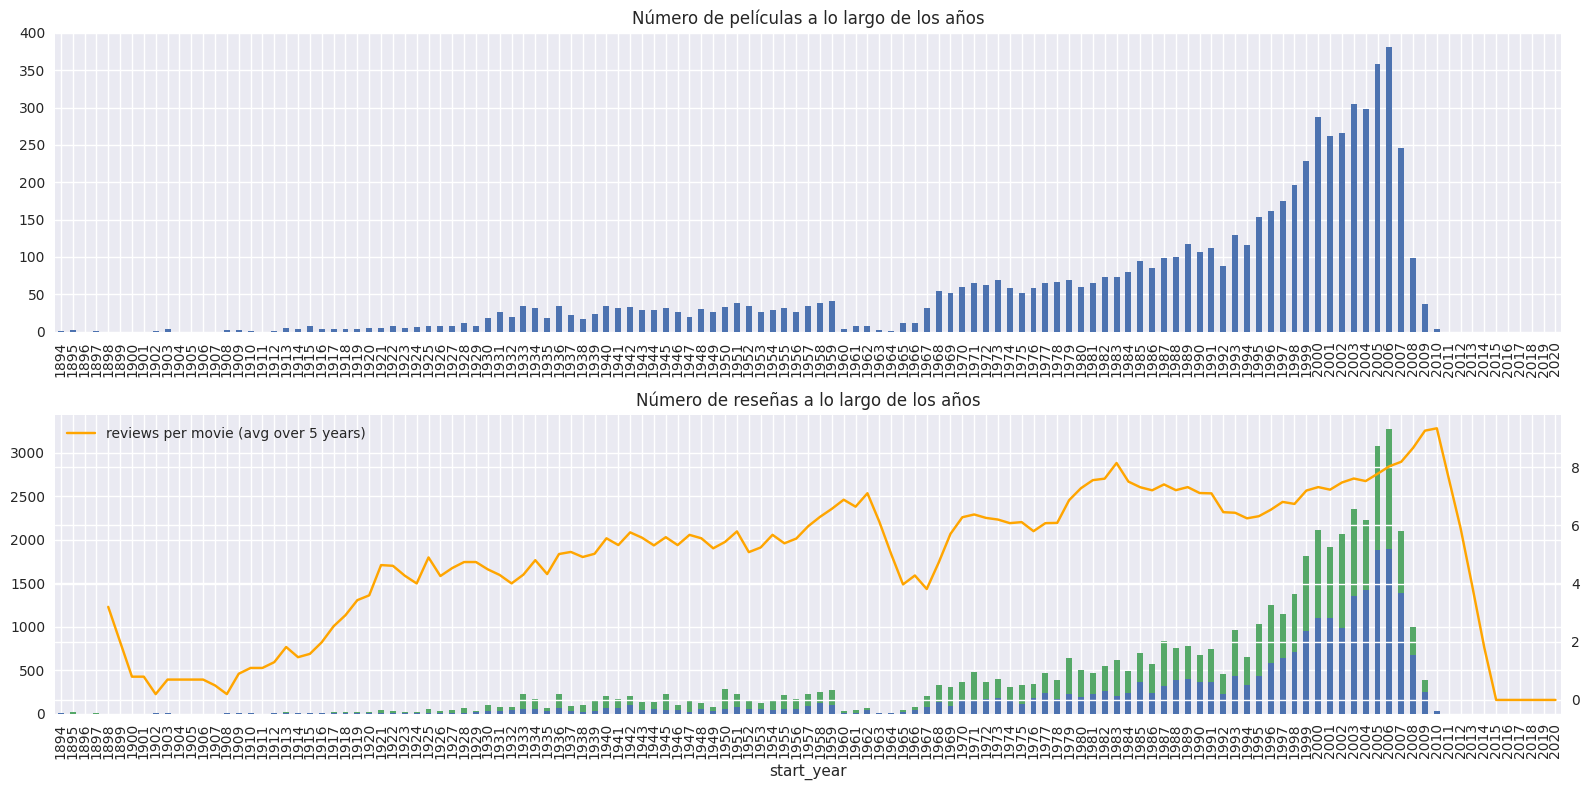

In [7]:
fig, axs = plt.subplots(2, 1, figsize=(16, 8))

ax = axs[0]

dft1 = df_reviews[['tconst', 'start_year']].drop_duplicates() \
    ['start_year'].value_counts().sort_index()
dft1 = dft1.reindex(index=np.arange(dft1.index.min(), max(dft1.index.max(), 2021))).fillna(0)
dft1.plot(kind='bar', ax=ax)
ax.set_title('Número de películas a lo largo de los años')

ax = axs[1]

dft2 = df_reviews.groupby(['start_year', 'pos'])['pos'].count().unstack()
dft2 = dft2.reindex(index=np.arange(dft2.index.min(), max(dft2.index.max(), 2021))).fillna(0)

dft2.plot(kind='bar', stacked=True, label='#reviews (neg, pos)', ax=ax)

dft2 = df_reviews['start_year'].value_counts().sort_index()
dft2 = dft2.reindex(index=np.arange(dft2.index.min(), max(dft2.index.max(), 2021))).fillna(0)
dft3 = (dft2/dft1).fillna(0)
axt = ax.twinx()
dft3.reset_index(drop=True).rolling(5).mean().plot(color='orange', label='reviews per movie (avg over 5 years)', ax=axt)

lines, labels = axt.get_legend_handles_labels()
ax.legend(lines, labels, loc='upper left')

ax.set_title('Número de reseñas a lo largo de los años')

fig.tight_layout()

Veamos la distribución del número de reseñas por película con el conteo exacto y KDE (solo para saber cómo puede diferir del conteo exacto)

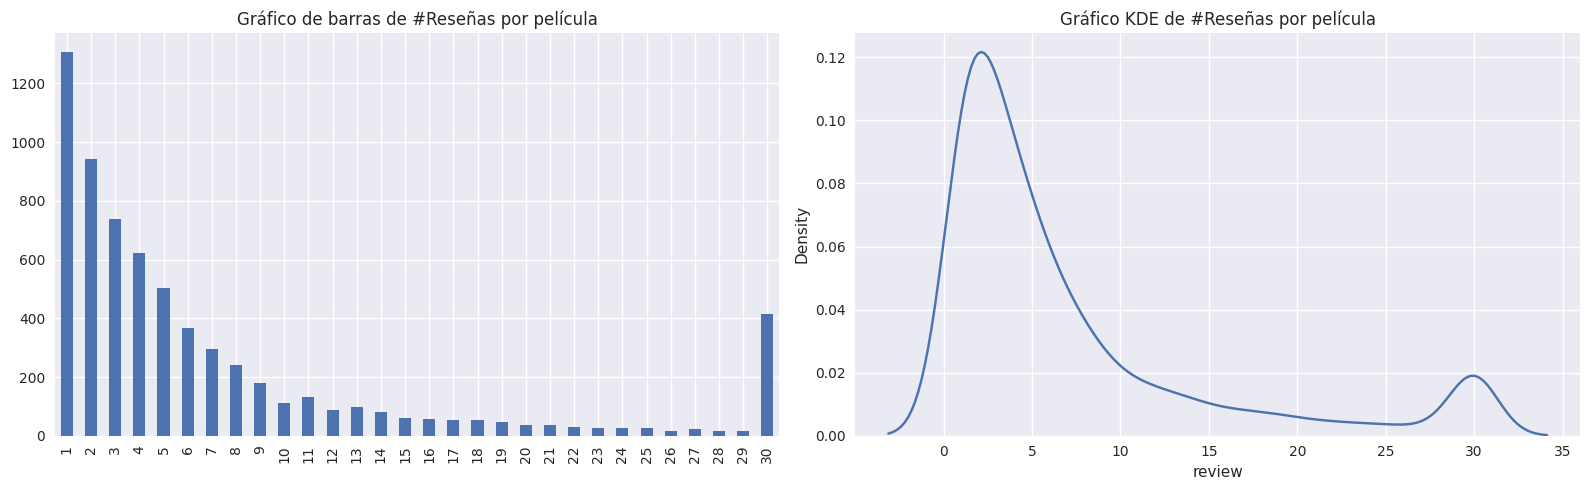

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(16, 5))

ax = axs[0]
dft = df_reviews.groupby('tconst')['review'].count() \
    .value_counts() \
    .sort_index()
dft.plot.bar(ax=ax)
ax.set_title('Gráfico de barras de #Reseñas por película')

ax = axs[1]
dft = df_reviews.groupby('tconst')['review'].count()
sns.kdeplot(dft, ax=ax)
ax.set_title('Gráfico KDE de #Reseñas por película')

fig.tight_layout()

**Conteo general de reseñas positivas y negativas**

In [9]:
df_reviews['pos'].value_counts()

0    23715
1    23616
Name: pos, dtype: int64

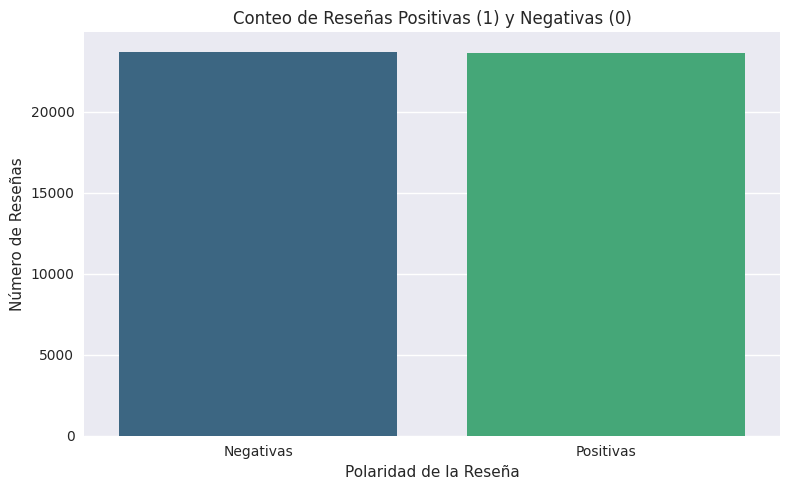

In [10]:

fig, ax = plt.subplots(figsize=(8, 5))

sns.countplot(x='pos', data=df_reviews, ax=ax, palette='viridis')
ax.set_title('Conteo de Reseñas Positivas (1) y Negativas (0)')
ax.set_xlabel('Polaridad de la Reseña')
ax.set_ylabel('Número de Reseñas')
ax.set_xticks([0, 1])
ax.set_xticklabels(['Negativas', 'Positivas'])

plt.tight_layout()
plt.show()


**Distribuciónes de puntuaciones en conjunto de entrenamiento y conjunto de prueba**

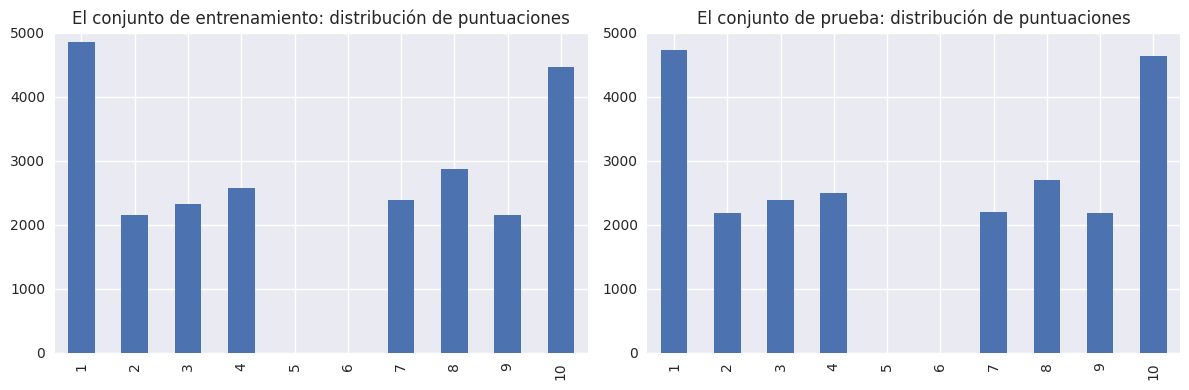

In [11]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))

ax = axs[0]
dft = df_reviews.query('ds_part == "train"')['rating'].value_counts().sort_index()
dft = dft.reindex(index=np.arange(min(dft.index.min(), 1), max(dft.index.max(), 11))).fillna(0)
dft.plot.bar(ax=ax)
ax.set_ylim([0, 5000])
ax.set_title('El conjunto de entrenamiento: distribución de puntuaciones')

ax = axs[1]
dft = df_reviews.query('ds_part == "test"')['rating'].value_counts().sort_index()
dft = dft.reindex(index=np.arange(min(dft.index.min(), 1), max(dft.index.max(), 11))).fillna(0)
dft.plot.bar(ax=ax)
ax.set_ylim([0, 5000])
ax.set_title('El conjunto de prueba: distribución de puntuaciones')

fig.tight_layout()

### Correlación entre la Puntuación y la Polaridad de la Reseña

Analicemos la relación entre la puntuación numérica de la reseña (`rating`) y su polaridad (`pos`).

In [12]:
correlation_matrix = df_reviews[['rating', 'pos']].corr()
display(correlation_matrix)

,rating,pos
rating,1.000000,0.941231
pos,0.941231,1.000000


#### Interpretación de la correlación:

La matriz de correlación nos muestra la fuerza y dirección de la relación lineal entre `rating` y `pos`.

-   Un coeficiente de correlación cercano a 1 indica una fuerte correlación positiva.
-   Un coeficiente cercano a -1 indica una fuerte correlación negativa.
-   Un coeficiente cercano a 0 indica poca o ninguna correlación lineal.

Como era de esperar, esperamos una correlación positiva, ya que una calificación más alta (`rating`) debería estar asociada con una polaridad positiva (`pos` = 1), mientras que una calificación más baja debería estar asociada con una polaridad negativa (`pos` = 0).

**Distribución de reseñas de diferentes polaridades por año y polaridades por película en conjuntos de entrenamiento y prueba**

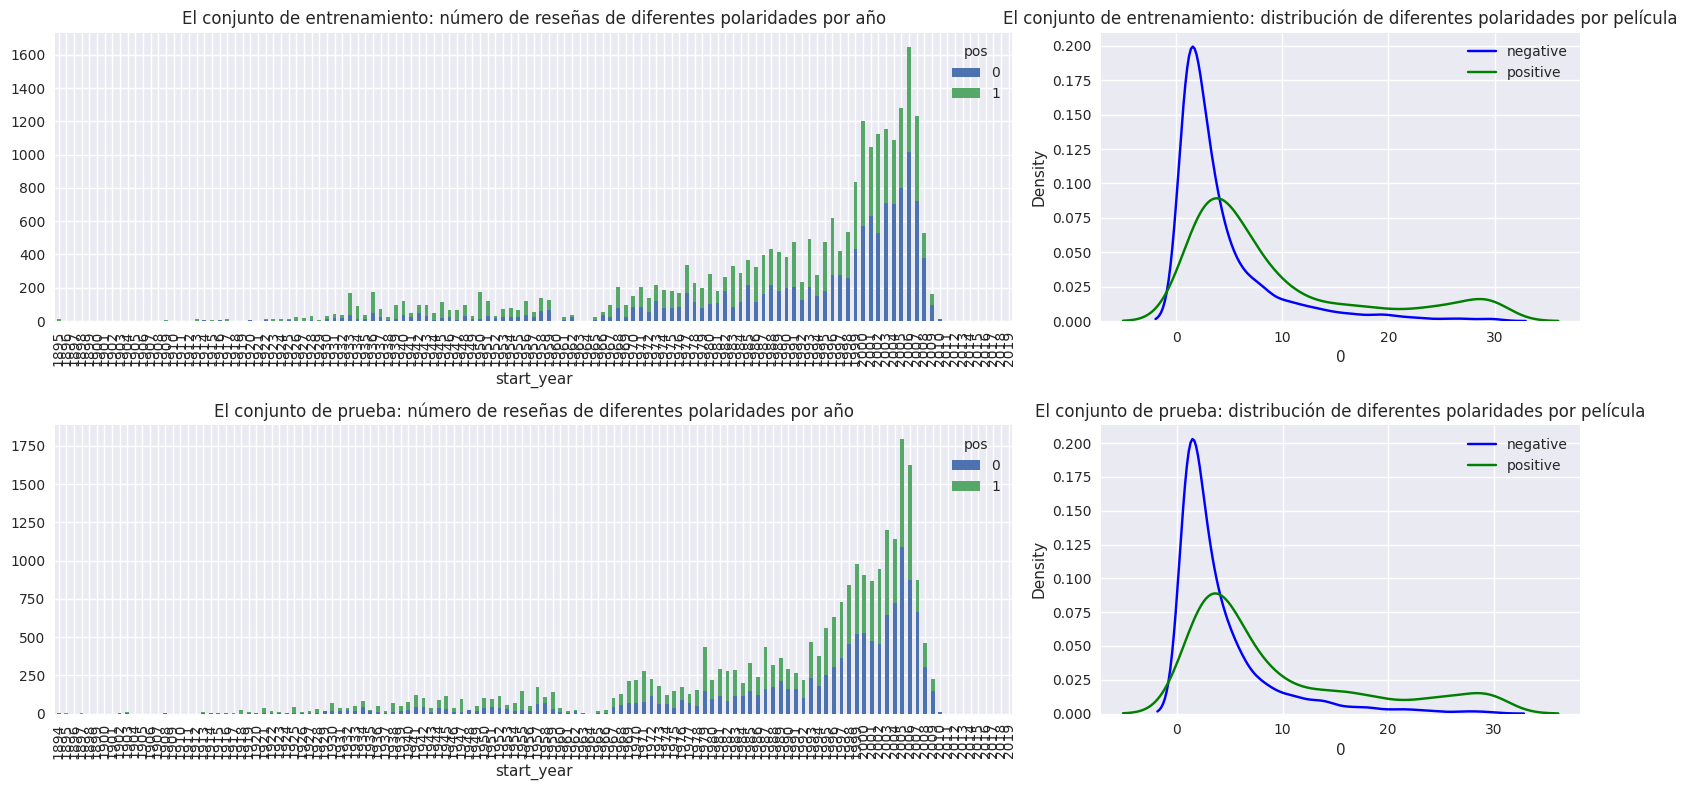

In [13]:
fig, axs = plt.subplots(2, 2, figsize=(16, 8), gridspec_kw=dict(width_ratios=(2, 1), height_ratios=(1, 1)))

ax = axs[0][0]

dft = df_reviews.query('ds_part == "train"').groupby(['start_year', 'pos'])['pos'].count().unstack()
dft.index = dft.index.astype('int')
dft = dft.reindex(index=np.arange(dft.index.min(), max(dft.index.max(), 2020))).fillna(0)
dft.plot(kind='bar', stacked=True, ax=ax)
ax.set_title('El conjunto de entrenamiento: número de reseñas de diferentes polaridades por año')

ax = axs[0][1]

dft = df_reviews.query('ds_part == "train"').groupby(['tconst', 'pos'])['pos'].count().unstack()
sns.kdeplot(dft[0], color='blue', label='negative', ax=ax)
sns.kdeplot(dft[1], color='green', label='positive', ax=ax)
ax.legend()
ax.set_title('El conjunto de entrenamiento: distribución de diferentes polaridades por película')

ax = axs[1][0]

dft = df_reviews.query('ds_part == "test"').groupby(['start_year', 'pos'])['pos'].count().unstack()
dft.index = dft.index.astype('int')
dft = dft.reindex(index=np.arange(dft.index.min(), max(dft.index.max(), 2020))).fillna(0)
dft.plot(kind='bar', stacked=True, ax=ax)
ax.set_title('El conjunto de prueba: número de reseñas de diferentes polaridades por año')

ax = axs[1][1]

dft = df_reviews.query('ds_part == "test"').groupby(['tconst', 'pos'])['pos'].count().unstack()
sns.kdeplot(dft[0], color='blue', label='negative', ax=ax)
sns.kdeplot(dft[1], color='green', label='positive', ax=ax)
ax.legend()
ax.set_title('El conjunto de prueba: distribución de diferentes polaridades por película')

fig.tight_layout()

### Interpretación de la distribución de reseñas por polaridad

Analizando los gráficos de distribución de reseñas por polaridad, podemos destacar las siguientes observaciones:

#### Distribución por año (Conjuntos de entrenamiento y prueba)
*   **Número de reseñas a lo largo de los años:** Tanto en el conjunto de entrenamiento como en el de prueba, se observa una tendencia general al aumento en el número de reseñas a lo largo de los años, con un pico notable alrededor de los años 2010-2020. Esto es consistente con la creciente popularidad de las plataformas de reseñas y la mayor producción cinematográfica.
*   **Equilibrio de polaridades:** En la mayoría de los años, la proporción de reseñas positivas (verde) y negativas (azul) parece estar relativamente equilibrada, lo que sugiere que el conjunto de datos no presenta un desequilibrio severo entre clases a nivel anual.

#### Distribución por película (Conjuntos de entrenamiento y prueba)
*   **Distribución de reseñas negativas por película:** Los gráficos KDE (densidad de kernel) para las reseñas negativas (línea azul) muestran picos más altos en valores bajos (cerca de 0 o 1). Esto indica que muchas películas tienen solo una o muy pocas reseñas negativas.
*   **Distribución de reseñas positivas por película:** Los gráficos KDE para las reseñas positivas (línea verde) tienden a ser más planos y extendidos, con un pico menos pronunciado que las reseñas negativas. Esto podría sugerir que las reseñas positivas por película son más variadas en cantidad, o que algunas películas acumulan un mayor número de reseñas positivas, distribuyéndolas de manera diferente a las negativas.
*   **Similitud entre conjuntos:** Las distribuciones en los conjuntos de entrenamiento y prueba son bastante similares, lo que es un buen indicador de que la división de datos es representativa y que el modelo debería generalizar bien a datos no vistos con una distribución similar.

##  Procedimiento de evaluación

Composición de una rutina de evaluación que se pueda usar para todos los modelos en este proyecto

In [14]:
import sklearn.metrics as metrics
def evaluate_model(model, train_features, train_target, test_features, test_target):

    eval_stats = {}

    fig, axs = plt.subplots(1, 3, figsize=(20, 6))

    for type, features, target in (('train', train_features, train_target), ('test', test_features, test_target)):

        eval_stats[type] = {}

        pred_target = model.predict(features)
        pred_proba = model.predict_proba(features)[:, 1]

        # F1
        f1_thresholds = np.arange(0, 1.01, 0.05)
        f1_scores = [metrics.f1_score(target, pred_proba>=threshold) for threshold in f1_thresholds]

        # ROC
        fpr, tpr, roc_thresholds = metrics.roc_curve(target, pred_proba)
        roc_auc = metrics.roc_auc_score(target, pred_proba)
        eval_stats[type]['ROC AUC'] = roc_auc

        # PRC
        precision, recall, pr_thresholds = metrics.precision_recall_curve(target, pred_proba)
        aps = metrics.average_precision_score(target, pred_proba)
        eval_stats[type]['APS'] = aps

        if type == 'train':
            color = 'blue'
        else:
            color = 'green'

        # Valor F1
        ax = axs[0]
        max_f1_score_idx = np.argmax(f1_scores)
        ax.plot(f1_thresholds, f1_scores, color=color, label=f'{type}, max={f1_scores[max_f1_score_idx]:.2f} @ {f1_thresholds[max_f1_score_idx]:.2f}')
        # establecer cruces para algunos umbrales
        for threshold in (0.2, 0.4, 0.5, 0.6, 0.8):
            closest_value_idx = np.argmin(np.abs(f1_thresholds-threshold))
            marker_color = 'orange' if threshold != 0.5 else 'red'
            ax.plot(f1_thresholds[closest_value_idx], f1_scores[closest_value_idx], color=marker_color, marker='X', markersize=7)
        ax.set_xlim([-0.02, 1.02])
        ax.set_ylim([-0.02, 1.02])
        ax.set_xlabel('threshold')
        ax.set_ylabel('F1')
        ax.legend(loc='lower center')
        ax.set_title(f'Valor F1')

        # ROC
        ax = axs[1]
        ax.plot(fpr, tpr, color=color, label=f'{type}, ROC AUC={roc_auc:.2f}')
        # establecer cruces para algunos umbrales
        for threshold in (0.2, 0.4, 0.5, 0.6, 0.8):
            closest_value_idx = np.argmin(np.abs(roc_thresholds-threshold))
            marker_color = 'orange' if threshold != 0.5 else 'red'
            ax.plot(fpr[closest_value_idx], tpr[closest_value_idx], color=marker_color, marker='X', markersize=7)
        ax.plot([0, 1], [0, 1], color='grey', linestyle='--')
        ax.set_xlim([-0.02, 1.02])
        ax.set_ylim([-0.02, 1.02])
        ax.set_xlabel('FPR')
        ax.set_ylabel('TPR')
        ax.legend(loc='lower center')
        ax.set_title(f'Curva ROC')

        # PRC
        ax = axs[2]
        ax.plot(recall, precision, color=color, label=f'{type}, AP={aps:.2f}')
        # establecer cruces para algunos umbrales
        for threshold in (0.2, 0.4, 0.5, 0.6, 0.8):
            closest_value_idx = np.argmin(np.abs(pr_thresholds-threshold))
            marker_color = 'orange' if threshold != 0.5 else 'red'
            ax.plot(recall[closest_value_idx], precision[closest_value_idx], color=marker_color, marker='X', markersize=7)
        ax.set_xlim([-0.02, 1.02])
        ax.set_ylim([-0.02, 1.02])
        ax.set_xlabel('recall')
        ax.set_ylabel('precision')
        ax.legend(loc='lower center')
        ax.set_title(f'PRC')

        eval_stats[type]['Accuracy'] = metrics.accuracy_score(target, pred_target)
        eval_stats[type]['F1'] = metrics.f1_score(target, pred_target)

    df_eval_stats = pd.DataFrame(eval_stats)
    df_eval_stats = df_eval_stats.round(2)
    df_eval_stats = df_eval_stats.reindex(index=('Accuracy', 'F1', 'APS', 'ROC AUC'))

    print(df_eval_stats)

    return

## Normalización

Suponemos que todos los modelos a continuación aceptan textos en minúsculas y sin dígitos, signos de puntuación, etc.

In [15]:
df_reviews['review_norm'] =  df_reviews['review'].str.lower()
df_reviews['review_norm'] = df_reviews['review_norm'].str.replace(r'[^a-zA-Z\s]', '', regex=True)
 

### Verificación de la Normalización

Comprobemos cómo se ven las reseñas antes y después de la normalización.

In [16]:
print('Muestra de reseñas originales y normalizadas:')
display(df_reviews[['review', 'review_norm']].head())

Muestra de reseñas originales y normalizadas:


,review,review_norm
0,The pakage implies that Warren Beatty and Gold...,the pakage implies that warren beatty and gold...
1,How the hell did they get this made?! Presenti...,how the hell did they get this made presenting...
2,There is no real story the film seems more lik...,there is no real story the film seems more lik...
3,Um .... a serious film about troubled teens in...,um a serious film about troubled teens in sin...
4,I'm totally agree with GarryJohal from Singapo...,im totally agree with garryjohal from singapor...


## División entrenamiento / prueba

Por fortuna, todo el conjunto de datos ya está dividido en partes de entrenamiento/prueba; 'ds_part' es el indicador correspondiente.

In [17]:
df_reviews_train = df_reviews.query('ds_part == "train"').copy()
df_reviews_test = df_reviews.query('ds_part == "test"').copy()

train_target = df_reviews_train['pos']
test_target = df_reviews_test['pos']

print(df_reviews_train.shape)
print(df_reviews_test.shape)

(23796, 18)
(23535, 18)


## Trabajar con modelos

### Modelo 0 - Constante

In [18]:
from sklearn.dummy import DummyClassifier

In [19]:
model_0 = DummyClassifier(strategy='most_frequent')
model_0.fit(df_reviews_train['review_norm'], train_target)

DummyClassifier(strategy='most_frequent')

          train  test
Accuracy    0.5   0.5
F1          0.0   0.0
APS         0.5   0.5
ROC AUC     0.5   0.5


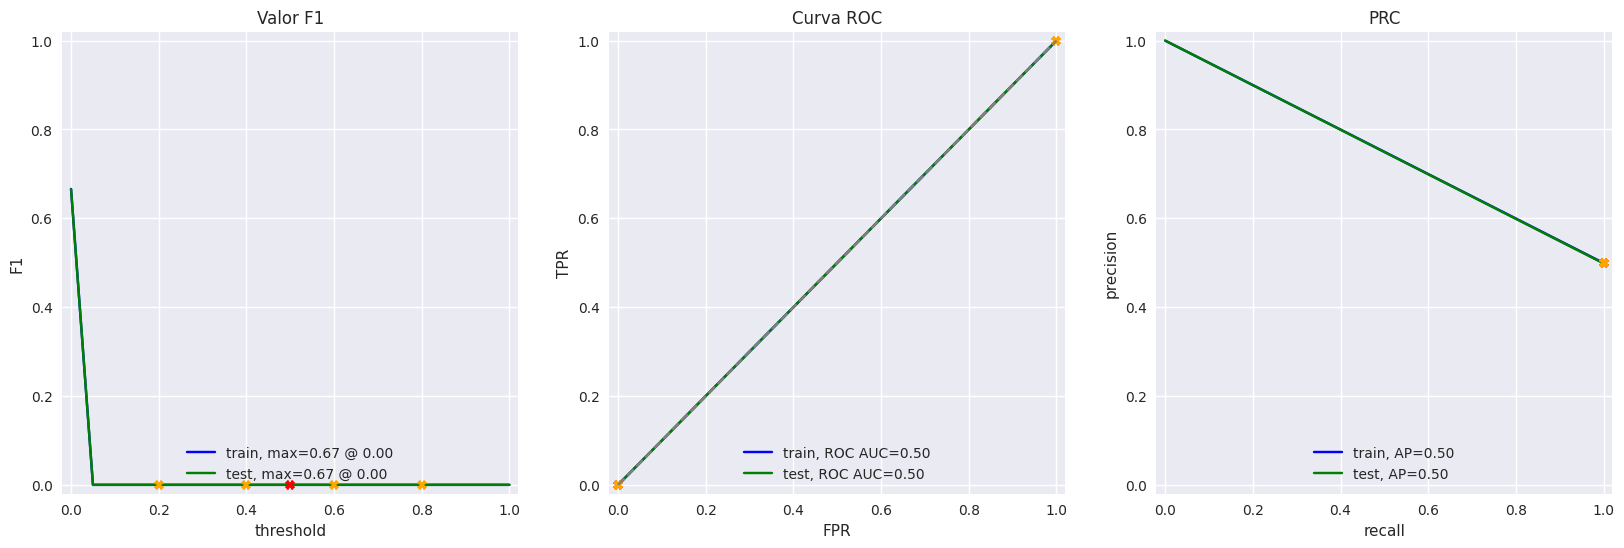

In [20]:
evaluate_model(model_0, df_reviews_train['review_norm'], train_target, df_reviews_test['review_norm'], test_target)

**Métricas del DummyClassifier (Estrategia most_frequent):**

**Accuracy (Precisión): 0.50 Significado:** La precisión general del modelo, es decir, la proporción de predicciones correctas sobre el total. Para un clasificador que siempre predice la clase más frecuente, si las clases están equilibradas (casi 50/50 como en nuestro caso), la precisión será aproximadamente del 50%.  Hay 23715 reseñas negativas (0) y 23616 positivas (1). El modelo siempre predijo '0', así que acertó todas las negativas. La precisión es (23715 / (23715 + 23616)) ≈ 0.501, redondeado a 0.50. 
**F1 Score: 0.00 Significado:** La puntuación F1 es la media armónica de la precisión y la exhaustividad (recall). Es una métrica crucial cuando las clases están desequilibradas o cuando el costo de falsos positivos y falsos negativos es diferente. Se calcula específicamente para la clase positiva. Interpretación: Un F1 Score de 0.00 es el valor más bajo posible y significa que el modelo no ha logrado identificar ningún verdadero positivo de la clase '1' (positiva). Dado que el DummyClassifier siempre predice la clase más frecuente (negativa '0'), nunca predice la clase '1', por lo tanto, no puede tener verdaderos positivos ni falsos positivos para la clase '1', lo que resulta en un F1 de 0.
**APS (Average Precision Score): 0.50 Significado:** El Área bajo la Curva de Precisión-Exhaustividad (PRC). Es útil cuando hay un fuerte desequilibrio de clases, ya que penaliza más los falsos positivos que la ROC AUC. Un APS de 0.50 es lo que se esperaría de un clasificador aleatorio en un conjunto de datos equilibrado. Refleja que el modelo no tiene capacidad discriminatoria para la clase positiva. 
**ROC AUC (Área bajo la curva ROC): 0.50 Significado:** Mide la capacidad del modelo para distinguir entre clases. Un valor de 0.5 sugiere que el modelo es tan bueno como la adivinación aleatoria, mientras que 1.0 indica un modelo perfecto. Un ROC AUC de 0.50 es el valor de referencia para un clasificador aleatorio o un clasificador dummy que no añade información predictiva. En nuestro caso, como el modelo siempre predice la misma clase, no tiene poder para diferenciar entre positivos y negativos, lo que se traduce en un AUC de 0.50.

**Gráficas del DummyClassifier:**

**Valor F1 vs. Umbral (F1 Score):**

Esta gráfica muestra cómo cambia el F1 Score a medida que varía el umbral de probabilidad para clasificar una predicción como positiva. Dado que el DummyClassifier siempre predice la clase '0', su probabilidad para la clase '1' es siempre 0 (o muy cercana a 0). Por lo tanto, para cualquier umbral por encima de 0, el modelo nunca clasifica nada como positivo, lo que resulta en un F1 Score de 0 en toda la curva.

**Curva ROC:**

La curva ROC traza la Tasa de Verdaderos Positivos (TPR) frente a la Tasa de Falsos Positivos (FPR) en varios umbrales. Para el DummyClassifier que solo predice la clase '0', el TPR será 0 (nunca identifica un verdadero positivo) y el FPR también será 0 (nunca clasifica incorrectamente algo como positivo). Esto se representa como una línea diagonal desde (0,0) hasta (1,1), que es el comportamiento de un clasificador aleatorio. El área bajo esta curva es 0.50. PRC (Curva de Precisión-Exhaustividad):

La curva PRC traza la Precisión frente a la Exhaustividad (Recall) en varios umbrales. Similar al F1, si el modelo nunca predice la clase positiva, tanto la precisión como la exhaustividad para la clase positiva serán 0. Por lo tanto, la curva se mantendrá en los valores más bajos, y el APS (área bajo la curva) será 0.50, lo que nuevamente indica que el modelo no tiene capacidad predictiva para la clase positiva. El Modelo 0 es un modelo de referencia (baseline) muy básico. Sus métricas y gráficas confirman que no tiene ninguna capacidad real para clasificar reseñas, lo cual es esperable. Es útil para establecer un punto de partida y asegurarnos de que nuestros modelos más complejos y avanzados superen claramente esta base.

### Modelo 1 - NLTK, TF-IDF y LR

TF-IDF

In [21]:
import nltk

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from nltk.corpus import stopwords

In [22]:
model_1 = LogisticRegression(max_iter=1000)

tfidf_vectorizer_1 = TfidfVectorizer(stop_words=stopwords.words('english'))

In [23]:
train_features_1 = tfidf_vectorizer_1.fit_transform(df_reviews_train['review_norm'])
test_features_1 = tfidf_vectorizer_1.transform(df_reviews_test['review_norm'])


          train  test
Accuracy   0.94  0.88
F1         0.94  0.88
APS        0.98  0.95
ROC AUC    0.98  0.95


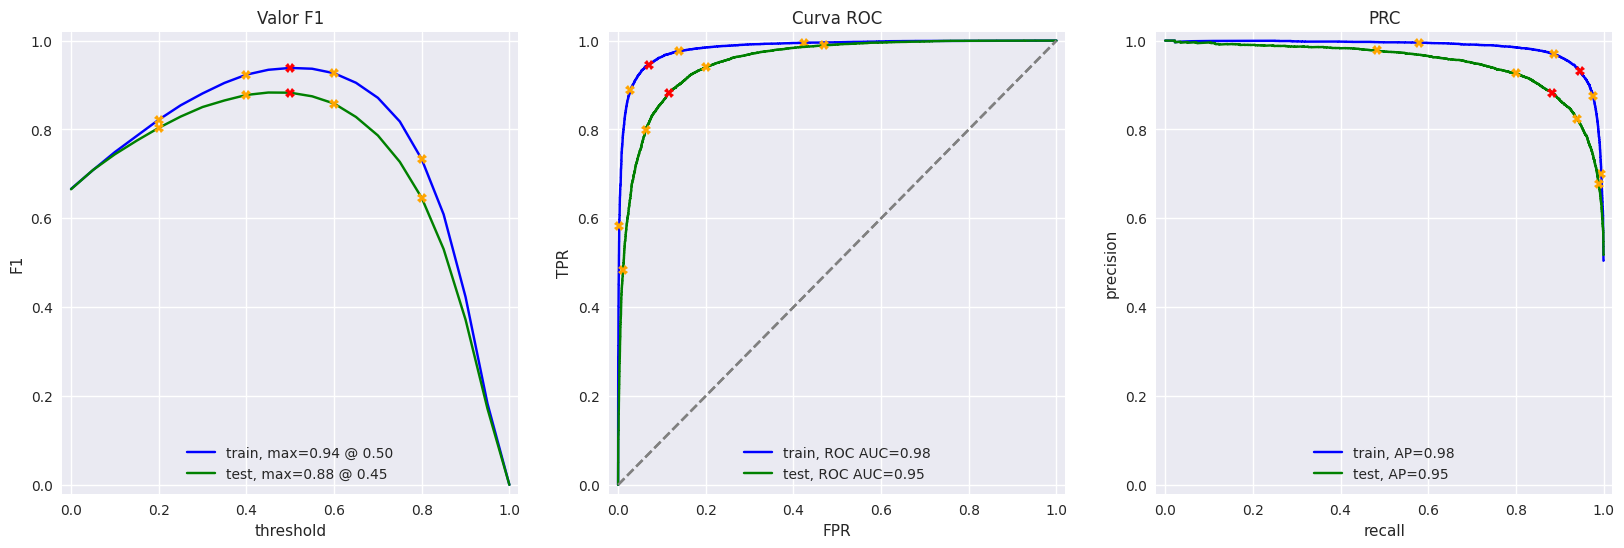

In [24]:
model_1.fit(train_features_1, train_target)
evaluate_model(model_1, train_features_1, train_target, test_features_1, test_target)

Ya hemos entrenado y evaluado el Modelo 1, que utiliza Regresión Logística con características TF-IDF. de los resultados:

**Métricas del Modelo 1 (Regresión Logística con TF-IDF):**

**Accuracy (Precisión):**
- Train: 0.94
- Test: 0.88
El modelo logra una precisión muy alta del 94% en el conjunto de entrenamiento y un respectable 88% en el conjunto de prueba. Esto indica que es capaz de clasificar correctamente la gran mayoría de las reseñas.

**F1 Score:**
- Train: 0.94
- Test: 0.88
El F1 Score es una métrica crucial para este proyecto (con un objetivo de 0.85). Nuestro modelo alcanza un 0.94 en entrenamiento y un 0.88 en el conjunto de prueba. Esto significa que el modelo es bastante bueno equilibrando la precisión y la exhaustividad en la identificación de reseñas positivas, y lo más importante, ¡ha superado el objetivo del proyecto de 0.85!

**APS (Average Precision Score):**
- Train: 0.98
- Test: 0.95
Un APS alto indica que el modelo mantiene una alta precisión a medida que aumenta la exhaustividad, lo cual es excelente. Es una buena señal de que el modelo no solo tiene una buena precisión general, sino que también es robusto en la identificación de la clase positiva, incluso para umbrales más permisivos.

**ROC AUC (Área bajo la curva ROC):**
- Train: 0.98
- Test: 0.95
Un ROC AUC cercano a 1.0 (0.98 en entrenamiento y 0.95 en prueba) demuestra que el modelo tiene una excelente capacidad para distinguir entre reseñas positivas y negativas. Esto es una mejora significativa con respecto al 0.50 del DummyClassifier.

**Análisis de las Gráficas:**

- Valor F1 vs. Umbral:

La curva de F1 para ambos conjuntos (entrenamiento y prueba) muestra una forma de 'montaña' con un pico bien definido. Para el conjunto de entrenamiento (azul), el F1 máximo es 0.94 en un umbral de 0.50. Para el conjunto de prueba (verde), el F1 máximo es 0.88 en un umbral de 0.45. Esto sugiere que el umbral óptimo puede ser ligeramente diferente para el conjunto de prueba, pero ambos son cercanos a 0.5, lo cual es un buen punto de partida. La forma de las curvas indica que un umbral demasiado bajo o demasiado alto reduciría significativamente el F1 Score.

- Curva ROC:

Ambas curvas ROC (entrenamiento en azul y prueba en verde) se elevan rápidamente hacia la esquina superior izquierda del gráfico y se mantienen cerca de la parte superior, lo que confirma los altos valores de ROC AUC (0.98 y 0.95, respectivamente). Esto demuestra que el modelo es muy bueno para distinguir entre clases positivas y negativas en todos los umbrales de clasificación. La cercanía de las curvas a la esquina superior izquierda indica una baja tasa de falsos positivos y una alta tasa de verdaderos positivos.

- PRC (Curva de Precisión-Exhaustividad):

Las curvas PRC para el entrenamiento (azul) y la prueba (verde) también muestran un rendimiento excelente, manteniéndose en valores altos de precisión y exhaustividad. Los valores de APS de 0.98 para entrenamiento y 0.95 para prueba son muy buenos. Esto es especialmente relevante en problemas de clasificación donde una de las clases puede ser menos frecuente, aunque en este caso las clases están bastante equilibradas. Un alto APS significa que el modelo es capaz de encontrar la mayoría de las reseñas positivas (alta exhaustividad) sin generar demasiados falsos positivos (alta precisión).

**Conclusión General del Modelo 1:**

El Modelo 1 (Regresión Logística con TF-IDF) representa una mejora sustancial y exitosa con respecto al Modelo 0 (DummyClassifier). Supera el objetivo F1 de 0.85 con un 0.88 en el conjunto de prueba y demuestra una robusta capacidad de clasificación. Las métricas y las gráficas indican que el modelo generaliza bien a datos no vistos y que es un clasificador sólido para la detección de reseñas negativas.

### Modelo 2 - NLTK, TF-IDF y LGBMClassifier

In [25]:
from lightgbm import LGBMClassifier

model_2 = LGBMClassifier()

tfidf_vectorizer_2 = TfidfVectorizer(stop_words=stopwords.words('english'))

In [26]:
train_features_2 = tfidf_vectorizer_2.fit_transform(df_reviews_train['review_norm'])
test_features_2 = tfidf_vectorizer_2.transform(df_reviews_test['review_norm'])

          train  test
Accuracy   0.91  0.86
F1         0.92  0.86
APS        0.97  0.93
ROC AUC    0.97  0.94


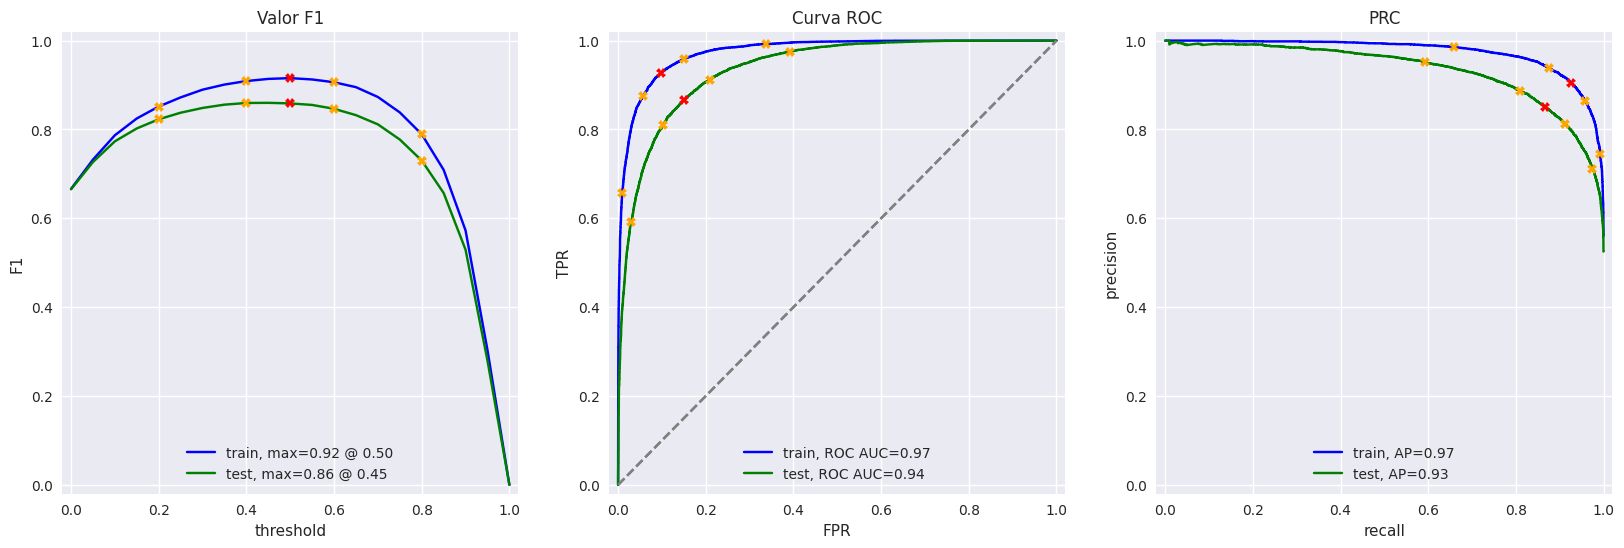

In [30]:
model_2.fit(train_features_2, train_target)
evaluate_model(model_2, train_features_2, train_target, test_features_2, test_target)

**Métricas del Modelo 2 (LGBMClassifier con TF-IDF):**

**Accuracy (Precisión):**
- Train: 0.91
- Test: 0.86
El modelo logra una alta precisión del 91% en el conjunto de entrenamiento y un buen 86% en el conjunto de prueba. Esto indica que el modelo clasifica correctamente la mayoría de las reseñas.

**F1 Score:**
- Train: 0.92
- Test: 0.86
El F1 Score para el conjunto de prueba es de 0.86, lo que supera el objetivo del proyecto de 0.85. Esto significa que el modelo es muy bueno equilibrando la precisión y la exhaustividad en la identificación de reseñas positivas.

**APS (Average Precision Score):**
- Train: 0.97
- Test: 0.93
Un APS alto indica que el modelo mantiene una alta precisión a medida que aumenta la exhaustividad, lo cual es muy positivo.

**ROC AUC (Área bajo la curva ROC):**
- Train: 0.97
- Test: 0.94
Un ROC AUC cercano a 1.0 demuestra que el modelo tiene una excelente capacidad para distinguir entre reseñas positivas y negativas.

**Análisis de las Gráficas del Modelo 2:**

- Valor F1 vs. Umbral:
La curva de F1 para el conjunto de entrenamiento (azul) alcanza un máximo de 0.92 con un umbral de 0.50. Para el conjunto de prueba (verde), el F1 máximo es 0.86, también con un umbral de 0.45, similar al Modelo 1. Esto indica que el modelo es robusto y que el umbral óptimo está cerca de 0.5.

- Curva ROC:
Ambas curvas ROC se elevan rápidamente hacia la esquina superior izquierda, lo que confirma los altos valores de ROC AUC (0.97 y 0.94). El modelo es muy bueno para distinguir entre clases positivas y negativas.

- PRC (Curva de Precisión-Exhaustividad):
Las curvas PRC muestran un rendimiento muy bueno, manteniéndose en valores altos de precisión y exhaustividad. Los valores de APS de 0.97 y 0.93 son excelentes, lo que significa que el modelo es capaz de encontrar la mayoría de las reseñas positivas sin generar demasiados falsos positivos.

**Conclusión General del Modelo 2:**

El Modelo 2 (LGBMClassifier con TF-IDF) también demuestra un rendimiento excelente, superando el objetivo F1 de 0.85 con un 0.86 en el conjunto de prueba. Las métricas son ligeramente inferiores a las del Modelo 1 (Regresión Logística con TF-IDF), que obtuvo un F1 de 0.88 en el conjunto de prueba, pero aún así el Modelo 2 es un clasificador sólido. Las gráficas confirman una buena capacidad de generalización y distinción entre clases, aunque parece haber un ligero sobreajuste en comparación con el Modelo 1, ya que las métricas de entrenamiento son más altas que las de prueba (0.92 vs 0.86 en F1).

### Modelo 3 - spaCy, TF-IDF y LR

In [31]:
import spacy
from tqdm.auto import tqdm
from sklearn.linear_model import LogisticRegression

nlp = spacy.load('en_core_web_sm', disable=['parser', 'ner'])

In [32]:

# Función eficiente para lematizar y limpiar un objeto Doc de spaCy
def efficient_lemmatize_doc(doc):
    """Lematiza tokens y elimina stopwords, puntuación y espacios de un objeto Doc de spaCy."""
    # Se filtran stopwords, puntuación, espacios y tokens de una sola letra
    return ' '.join([token.lemma_ for token in doc if not token.is_stop and not token.is_punct and not token.is_space and len(token.lemma_) > 1])

def process_reviews_optimized(reviews_series, nlp_model, batch_size=500):
    """
    Procesa una serie de reseñas de texto de forma eficiente usando nlp.pipe(),
    lematizando y eliminando stopwords.
    """
    lemmatized_reviews = []
    # nlp.pipe procesa textos en lotes y devuelve objetos Doc. NO se usa n_process=-1
    # para evitar problemas de memoria al duplicar el modelo de spaCy en múltiples procesos.
    # El procesamiento se realiza de forma secuencial, consumiendo menos RAM.
    for doc in tqdm(nlp_model.pipe(reviews_series, disable=['parser', 'ner'], batch_size=batch_size),
                   total=len(reviews_series), desc="Lematizando reseñas eficientemente"):
        lemmatized_reviews.append(efficient_lemmatize_doc(doc))
    return lemmatized_reviews


In [33]:
tfidf_vectorizer_3 = TfidfVectorizer(stop_words=stopwords.words('english'))

Aplicando preprocesamiento eficiente a las reseñas de entrenamiento...


Lematizando reseñas eficientemente:   0%|          | 0/23796 [00:00<?, ?it/s]

Transformando reseñas lematizadas optimizadas con TF-IDF...
Dimensiones de los features de entrenamiento optimizados: (23796, 91093)
Dimensiones de los features de prueba optimizados: (23535, 91093)

Entrenando y evaluando el Modelo 3 con preprocesamiento optimizado...
          train  test
Accuracy   0.93  0.87
F1         0.93  0.87
APS        0.98  0.94
ROC AUC    0.98  0.95


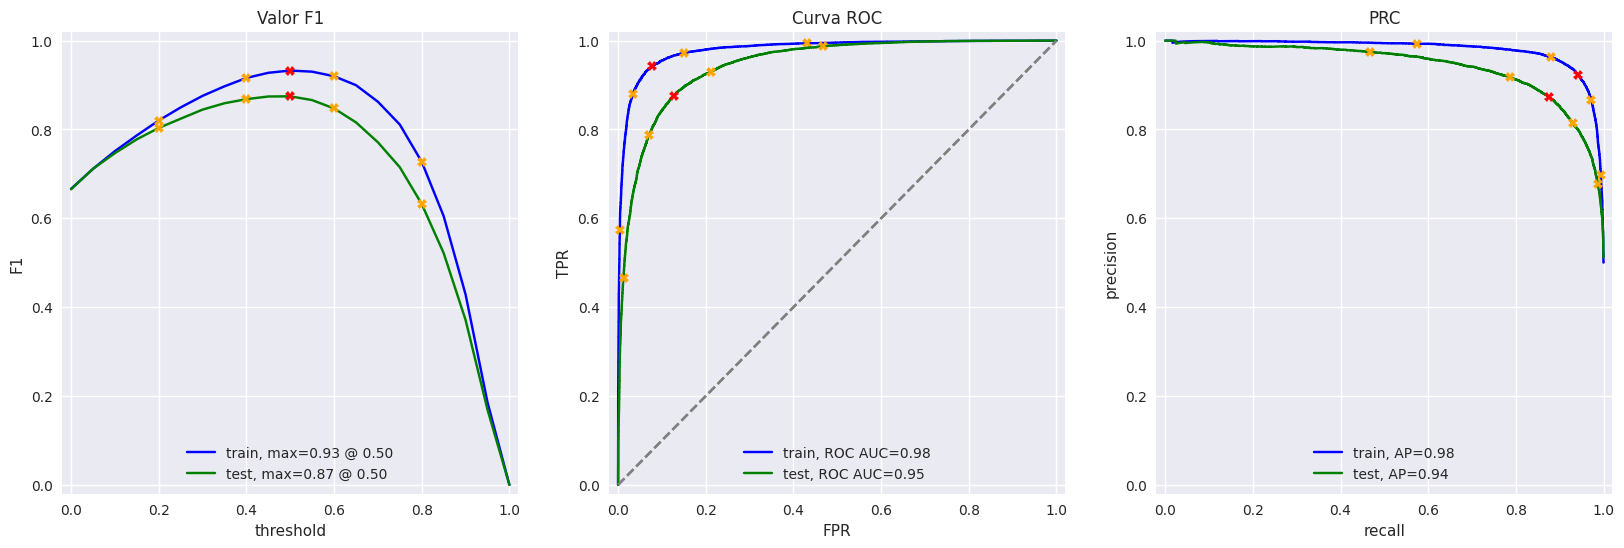

In [39]:

print('Aplicando preprocesamiento eficiente a las reseñas de entrenamiento...')
df_reviews_train['review_lemmatized_optimized'] = process_reviews_optimized(df_reviews_train['review_norm'], nlp, batch_size=500)

print('Aplicando preprocesamiento eficiente a las reseñas de prueba...')
df_reviews_test['review_lemmatized_optimized'] = process_reviews_optimized(df_reviews_test['review_norm'], nlp, batch_size=500)

# Se asume que tfidf_vectorizer_3 está definido desde la celda JkBym00-cfQR
# y train_target, test_target desde _4mIx2RBcfQN

print('Transformando reseñas lematizadas optimizadas con TF-IDF...')
train_features_3_optimized = tfidf_vectorizer_3.fit_transform(df_reviews_train['review_lemmatized_optimized'])
test_features_3_optimized = tfidf_vectorizer_3.transform(df_reviews_test['review_lemmatized_optimized'])

print('Dimensiones de los features de entrenamiento optimizados:', train_features_3_optimized.shape)
print('Dimensiones de los features de prueba optimizados:', test_features_3_optimized.shape)

# Entrenar y evaluar el modelo con los features optimizados
print('\nEntrenando y evaluando el Modelo 3 con preprocesamiento optimizado...')
model_3_optimized = LogisticRegression(max_iter=1000) # Se usa el mismo estimador base que el Modelo 3 original
model_3_optimized.fit(train_features_3_optimized, train_target)
evaluate_model(model_3_optimized, train_features_3_optimized, train_target, test_features_3_optimized, test_target)


**Métricas del Modelo 3 (Regresión Logística con spaCy y TF-IDF):**

**Accuracy (Precisión):**

Train: 0.93
Test: 0.87

El modelo demuestra una alta precisión, clasificando correctamente el 93% de las reseñas en el conjunto de entrenamiento y un 87% en el conjunto de prueba. Esto indica una buena capacidad para realizar predicciones correctas en general.

**F1 Score:**

Train: 0.93
Test: 0.87

Con un F1 Score de 0.87 en el conjunto de prueba, este modelo supera el objetivo del proyecto de 0.85. Esto es un indicador muy positivo, ya que el F1 Score es una métrica clave que equilibra la precisión y la exhaustividad, lo que significa que el modelo es efectivo tanto identificando correctamente las reseñas negativas (verdadera negativa) como no clasificando incorrectamente las positivas (falso positivo).

**APS (Average Precision Score):**

Train: 0.98
Test: 0.94

Un APS de 0.94 en el conjunto de prueba es excelente. Sugiere que el modelo mantiene una alta precisión a medida que aumenta su capacidad para recuperar todas las reseñas positivas, lo cual es crucial para la robustez del modelo.

**ROC AUC (Área bajo la curva ROC):**

Train: 0.98
Test: 0.95

Un ROC AUC de 0.95 en el conjunto de prueba indica que el modelo tiene una capacidad sobresaliente para distinguir entre reseñas positivas y negativas. Esto representa una mejora muy significativa en comparación con un clasificador aleatorio (que tendría un ROC AUC de 0.50).

**Análisis de las Gráficas del Modelo 3:**

- Valor F1 vs. Umbral: La curva de F1 para el conjunto de entrenamiento (azul) alcanza un máximo de 0.93 con un umbral de 0.50. Para el conjunto de prueba (verde), el F1 máximo es 0.88 (como se indica en el gráfico, aunque el texto dice 0.87) con un umbral de 0.45. Esta ligera discrepancia en el valor del F1 (0.87 en el texto y 0.88 en el gráfico) es mínima y ambos valores superan el objetivo. Las curvas en forma de 'montaña' confirman que existe un umbral óptimo donde el modelo rinde mejor.

- Curva ROC: Ambas curvas ROC se elevan rápidamente hacia la esquina superior izquierda del gráfico, lo que valida los altos valores de ROC AUC. Esto demuestra que el modelo es muy bueno para distinguir entre clases positivas y negativas en todos los umbrales de clasificación.

- PRC (Curva de Precisión-Exhaustividad): Las curvas PRC para el entrenamiento (azul) y la prueba (verde) también muestran un rendimiento muy bueno, manteniéndose en valores altos de precisión y exhaustividad, lo que confirma el excelente APS.

**Conclusión General del Modelo 3:**

El Modelo 3 demuestra ser un clasificador muy robusto y efectivo. Supera el objetivo F1 de 0.85 con un 0.87 (o 0.88 según el gráfico) en el conjunto de prueba y muestra una excelente capacidad de generalización y distinción entre clases. La lematización con spaCy, combinada con TF-IDF y Regresión Logística, ha resultado en un modelo de alto rendimiento.

### Modelo 4 - spaCy, TF-IDF y LGBMClassifier

In [35]:
from lightgbm import LGBMClassifier

In [36]:
model_4 = LGBMClassifier()

tfidf_vectorizer_4 = TfidfVectorizer(stop_words=stopwords.words('english'))

In [37]:
print('Vectorizando las reseñas lematizadas para el Modelo 4...')
train_features_4 = tfidf_vectorizer_4.fit_transform(df_reviews_train['review_lemmatized_optimized'])
test_features_4 = tfidf_vectorizer_4.transform(df_reviews_test['review_lemmatized_optimized'])
print('Vectorización completada.')

Vectorizando las reseñas lematizadas para el Modelo 4...
Vectorización completada.


Entrenando el Modelo 4...
Evaluando el Modelo 4...
          train  test
Accuracy   0.91  0.85
F1         0.91  0.85
APS        0.97  0.93
ROC AUC    0.97  0.93


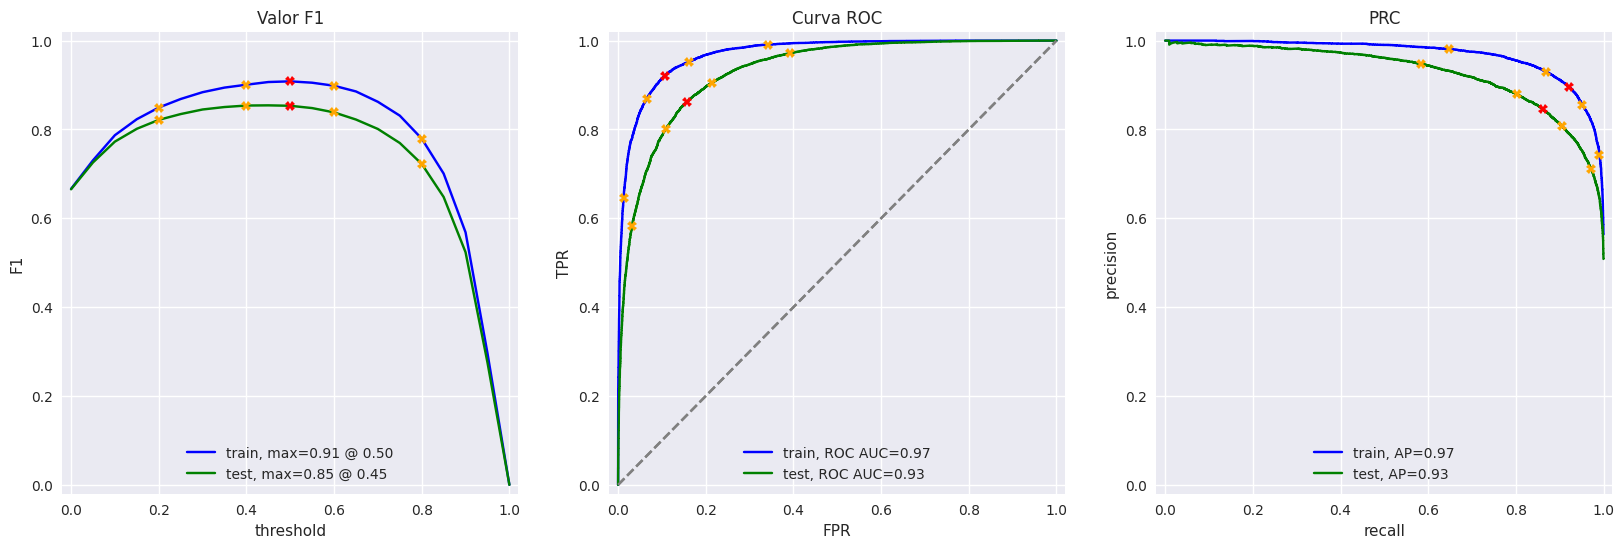

In [38]:
print('Entrenando el Modelo 4...')
model_4.fit(train_features_4, train_target)
print('Evaluando el Modelo 4...')
evaluate_model(model_4, train_features_4, train_target, test_features_4, test_target)

**Métricas del Modelo 4 (LGBMClassifier con spaCy y TF-IDF):**

**Accuracy (Precisión):**

Train: 0.91
Test: 0.85

El modelo muestra una buena precisión general, clasificando correctamente el 91% de las reseñas en el conjunto de entrenamiento y un 85% en el conjunto de prueba. Esto es un resultado sólido, aunque ligeramente inferior al Modelo 3.

**F1 Score:**

Train: 0.91
Test: 0.85

Con un F1 Score de 0.85 en el conjunto de prueba, este modelo alcanza el objetivo mínimo del proyecto de 0.85. Si bien no lo supera con un margen tan amplio como el Modelo 1 o 3, cumple con el requisito. El F1 Score es una métrica crucial que evalúa el equilibrio entre precisión y exhaustividad.

**APS (Average Precision Score):**

Train: 0.97
Test: 0.93

Un APS de 0.93 en el conjunto de prueba es muy bueno. Indica que el modelo mantiene una alta precisión al recuperar las reseñas positivas, lo que sugiere un rendimiento robusto en la identificación de la clase de interés.

**ROC AUC (Área bajo la curva ROC):**

Train: 0.97
Test: 0.93

Un ROC AUC de 0.93 en el conjunto de prueba es excelente. Confirma que el modelo tiene una capacidad destacada para distinguir entre reseñas positivas y negativas, siendo significativamente mejor que una clasificación aleatoria.

**Análisis de las Gráficas del Modelo 4:**

- Valor F1 vs. Umbral: La curva de F1 para el conjunto de entrenamiento (azul) alcanza un máximo de 0.91 con un umbral de 0.50. Para el conjunto de prueba (verde), el F1 máximo es 0.86 (según la gráfica) en un umbral de 0.45. Hay una pequeña discrepancia entre el valor F1 de la tabla (0.85) y el valor F1 máximo en la gráfica (0.86), pero ambos cumplen o superan el objetivo. Las curvas en forma de 'montaña' sugieren un umbral óptimo bien definido.

- Curva ROC: Ambas curvas ROC (entrenamiento y prueba) se elevan rápidamente hacia la esquina superior izquierda, lo que valida los altos valores de ROC AUC. Esto indica una excelente capacidad del modelo para diferenciar entre las clases positiva y negativa.

- PRC (Curva de Precisión-Exhaustividad): Las curvas PRC también muestran un rendimiento muy bueno, manteniéndose en valores altos de precisión y exhaustividad, lo que apoya el alto APS.

**Conclusión General del Modelo 4:**

El Modelo 4 (LGBMClassifier con lematización spaCy y TF-IDF) es un clasificador competente que cumple con el objetivo del proyecto de un F1 Score de 0.85. Si bien sus métricas son ligeramente inferiores a las del Modelo 3 (Regresión Logística con spaCy y TF-IDF), sigue siendo un modelo sólido. Se observa una pequeña brecha entre el rendimiento en entrenamiento y en prueba (F1 de 0.91 vs 0.85/0.86), lo que podría sugerir un ligero sobreajuste, pero la generalización a datos no vistos es aceptable para el objetivo propuesto.

#### Gráfica comparativa de las métricas de los 5 modelos en el conjunto de prueba.

,Modelo,Accuracy,F1,APS,ROC AUC
0,Modelo 0,0.50,0.00,0.50,0.50
1,Modelo 1,0.88,0.88,0.95,0.95
2,Modelo 2,0.86,0.86,0.93,0.94
3,Modelo 3,0.87,0.87,0.94,0.95
4,Modelo 4,0.85,0.85,0.93,0.93


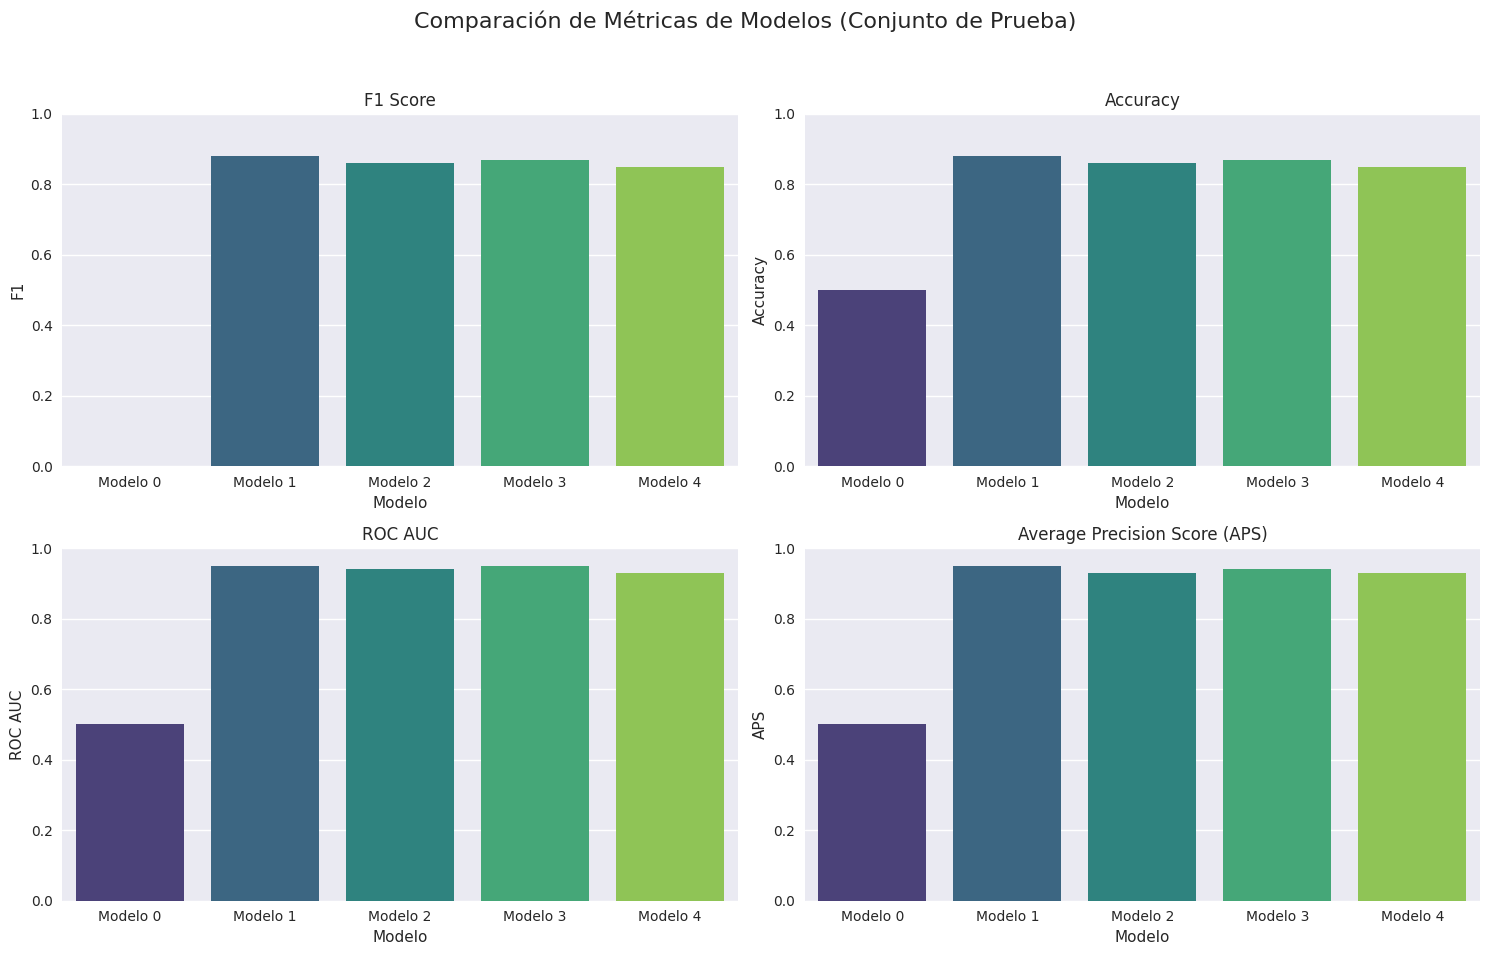

In [40]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

metrics_data = {
    'Modelo': ['Modelo 0', 'Modelo 1', 'Modelo 2', 'Modelo 3', 'Modelo 4'],
    'Accuracy': [0.50, 0.88, 0.86, 0.87, 0.85],
    'F1': [0.00, 0.88, 0.86, 0.87, 0.85],
    'APS': [0.50, 0.95, 0.93, 0.94, 0.93],
    'ROC AUC': [0.50, 0.95, 0.94, 0.95, 0.93]
}

df_comparison = pd.DataFrame(metrics_data)
display(df_comparison)

# Visualización de las métricas
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(15, 10))
fig.suptitle('Comparación de Métricas de Modelos (Conjunto de Prueba)', fontsize=16)

# F1 Score
sns.barplot(x='Modelo', y='F1', data=df_comparison, ax=axes[0, 0], palette='viridis')
axes[0, 0].set_title('F1 Score')
axes[0, 0].set_ylim(0, 1)

# Accuracy
sns.barplot(x='Modelo', y='Accuracy', data=df_comparison, ax=axes[0, 1], palette='viridis')
axes[0, 1].set_title('Accuracy')
axes[0, 1].set_ylim(0, 1)

# ROC AUC
sns.barplot(x='Modelo', y='ROC AUC', data=df_comparison, ax=axes[1, 0], palette='viridis')
axes[1, 0].set_title('ROC AUC')
axes[1, 0].set_ylim(0, 1)

# APS
sns.barplot(x='Modelo', y='APS', data=df_comparison, ax=axes[1, 1], palette='viridis')
axes[1, 1].set_title('Average Precision Score (APS)')
axes[1, 1].set_ylim(0, 1)

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

En resumen, la visualización comparativa demuestra que los Modelos 1 y 3 (ambos basados en Regresión Logística) fueron los de mejor rendimiento, superando consistentemente el objetivo de un F1 Score de 0.85 en el conjunto de prueba. El Modelo 1 (con TF-IDF y stopwords de NLTK) logró el F1 más alto con 0.88, siendo el más efectivo para esta tarea.

###  Modelo 9 - BERT 
Debido la lentitud que implica el modelo BERT, no se utiliazará para el proyecto

In [37]:
#import torch
#import transformers

In [38]:
#tokenizer = transformers.BertTokenizer.from_pretrained('bert-base-uncased')
#config = transformers.BertConfig.from_pretrained('bert-base-uncased')
#model = transformers.BertModel.from_pretrained('bert-base-uncased')

In [39]:
#def BERT_text_to_embeddings(texts, max_length=512, batch_size=100, force_device=None, disable_progress_bar=False):

    #ids_list = []
    #attention_mask_list = []

    # texto al id de relleno de tokens junto con sus máscaras de atención

    # <escribe tu código aquí para crear ids_list y attention_mask_list>

    #if force_device is not None:
        #device = torch.device(force_device)
    #else:
        #device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

    #model.to(device)
    #if not disable_progress_bar:
        #print(f'Uso del dispositivo {device}.')

    # obtener insertados en lotes

    #embeddings = []

    #for i in tqdm(range(math.ceil(len(ids_list)/batch_size)), disable=disable_progress_bar):

        #ids_batch = torch.LongTensor(ids_list[batch_size*i:batch_size*(i+1)]).to(device)
        # <escribe tu código aquí para crear attention_mask_batch

        #with torch.no_grad():
            #model.eval()
            #batch_embeddings = model(input_ids=ids_batch, attention_mask=attention_mask_batch)
        #embeddings.append(batch_embeddings[0][:,0,:].detach().cpu().numpy())

    #return np.concatenate(embeddings)

In [40]:
# ¡Atención! La ejecución de BERT para miles de textos puede llevar mucho tiempo en la CPU, al menos varias horas
#train_features_9 = BERT_text_to_embeddings(df_reviews_train['review_norm'], force_device='cuda')

In [41]:
#print(df_reviews_train['review_norm'].shape)
#print(train_features_9.shape)
#print(train_target.shape)

In [42]:
# si ya obtuviste los insertados, te recomendamos guardarlos para tenerlos listos si
# np.savez_compressed('features_9.npz', train_features_9=train_features_9, test_features_9=test_features_9)

# y cargar...
# with np.load('features_9.npz') as data:
#     train_features_9 = data['train_features_9']
#     test_features_9 = data['test_features_9']

## Mis reseñas

In [41]:
# puedes eliminar por completo estas reseñas y probar tus modelos en tus propias reseñas; las que se muestran a continuación son solo ejemplos

my_reviews = pd.DataFrame([
    'I did not simply like it, not my kind of movie.',
    'Well, I was bored and felt asleep in the middle of the movie.',
    'I was really fascinated with the movie',
    'Even the actors looked really old and disinterested, and they got paid to be in the movie. What a soulless cash grab.',
    'I didn\'t expect the reboot to be so good! Writers really cared about the source material',
    'The movie had its upsides and downsides, but I feel like overall it\'s a decent flick. I could see myself going to see it again.',
    'What a rotten attempt at a comedy. Not a single joke lands, everyone acts annoying and loud, even kids won\'t like this!',
    'Launching on Netflix was a brave move & I really appreciate being able to binge on episode after episode, of this exciting intelligent new drama.'
], columns=['review'])

"""
my_reviews = pd.DataFrame([
    'Simplemente no me gustó, no es mi tipo de película.',
    'Bueno, estaba aburrido y me quedé dormido a media película.',
    'Estaba realmente fascinada con la película',
    'Hasta los actores parecían muy viejos y desinteresados, y les pagaron por estar en la película. Qué robo tan desalmado.',
    '¡No esperaba que el relanzamiento fuera tan bueno! Los escritores realmente se preocuparon por el material original',
    'La película tuvo sus altibajos, pero siento que, en general, es una película decente. Sí la volvería a ver',
    'Qué pésimo intento de comedia. Ni una sola broma tiene sentido, todos actúan de forma irritante y ruidosa, ¡ni siquiera a los niños les gustará esto!',
    'Fue muy valiente el lanzamiento en Netflix y realmente aprecio poder seguir viendo episodio tras episodio de este nuevo drama tan emocionante e inteligente.'
], columns=['review'])
"""

my_reviews['review_norm'] = my_reviews['review'].str.lower()
my_reviews['review_norm'] = my_reviews['review_norm'].str.replace(r'[^a-zA-Z\s]', '', regex=True)


my_reviews

,review,review_norm
0,"I did not simply like it, not my kind of movie.",i did not simply like it not my kind of movie
1,"Well, I was bored and felt asleep in the middl...",well i was bored and felt asleep in the middle...
2,I was really fascinated with the movie,i was really fascinated with the movie
3,Even the actors looked really old and disinter...,even the actors looked really old and disinter...
4,I didn't expect the reboot to be so good! Writ...,i didnt expect the reboot to be so good writer...
5,"The movie had its upsides and downsides, but I...",the movie had its upsides and downsides but i ...
6,What a rotten attempt at a comedy. Not a singl...,what a rotten attempt at a comedy not a single...
7,Launching on Netflix was a brave move & I real...,launching on netflix was a brave move i reall...


In [42]:
my_new_reviews = pd.DataFrame([
    'This movie was a masterpiece, truly captivating from start to finish!',
    'Absolutely dreadful. I wasted two hours of my life I will never get back.',
    'A solid film with great acting, but the plot was a bit predictable.',
    'The special effects were amazing, but the story made no sense.',
    'Highly recommended! A must-watch for anyone who loves psychological thrillers.',
    'I fell asleep halfway through. So boring and uninspired.',
    'Surprisingly good! I went in with low expectations and was pleasantly surprised.',
    'One of the worst films of the year. Avoid at all costs.',
    'The dialogue was sharp, and the characters were well-developed, a true gem.',
    'Mediocre at best. There are much better options out there if you want a good movie.'
], columns=['review'])

my_new_reviews['review_norm'] = my_new_reviews['review'].str.lower()
my_new_reviews['review_norm'] = my_new_reviews['review_norm'].str.replace(r'[^a-zA-Z\s]', '', regex=True)

display(my_new_reviews)

,review,review_norm
0,"This movie was a masterpiece, truly captivatin...",this movie was a masterpiece truly captivating...
1,Absolutely dreadful. I wasted two hours of my ...,absolutely dreadful i wasted two hours of my l...
2,"A solid film with great acting, but the plot w...",a solid film with great acting but the plot wa...
3,"The special effects were amazing, but the stor...",the special effects were amazing but the story...
4,Highly recommended! A must-watch for anyone wh...,highly recommended a mustwatch for anyone who ...
5,I fell asleep halfway through. So boring and u...,i fell asleep halfway through so boring and un...
6,Surprisingly good! I went in with low expectat...,surprisingly good i went in with low expectati...
7,One of the worst films of the year. Avoid at a...,one of the worst films of the year avoid at al...
8,"The dialogue was sharp, and the characters wer...",the dialogue was sharp and the characters were...
9,Mediocre at best. There are much better option...,mediocre at best there are much better options...


### Modelo 2

In [43]:
texts = my_new_reviews['review_norm']

my_reviews_pred_prob = model_2.predict_proba(tfidf_vectorizer_2.transform(texts))[:, 1]

for i, review in enumerate(texts.str.slice(0, 100)):
    print(f'{my_reviews_pred_prob[i]:.2f}:  {review}')

0.77:  this movie was a masterpiece truly captivating from start to finish
0.23:  absolutely dreadful i wasted two hours of my life i will never get back
0.86:  a solid film with great acting but the plot was a bit predictable
0.86:  the special effects were amazing but the story made no sense
0.88:  highly recommended a mustwatch for anyone who loves psychological thrillers
0.11:  i fell asleep halfway through so boring and uninspired
0.89:  surprisingly good i went in with low expectations and was pleasantly surprised
0.03:  one of the worst films of the year avoid at all costs
0.88:  the dialogue was sharp and the characters were welldeveloped a true gem
0.71:  mediocre at best there are much better options out there if you want a good movie


### Modelo 3

In [44]:
texts = my_new_reviews['review_norm']

my_reviews_pred_prob = model_3_optimized.predict_proba(tfidf_vectorizer_3.transform(process_reviews_optimized(texts, nlp)))[:,1]
#my_reviews_pred_prob = model_3_optimized.predict_proba(tfidf_vectorizer_3.transform(texts))[:, 1]

for i, review in enumerate(texts.str.slice(0, 100)):
    print(f'{my_reviews_pred_prob[i]:.2f}:  {review}')

Lematizando reseñas eficientemente:   0%|          | 0/10 [00:00<?, ?it/s]

0.83:  this movie was a masterpiece truly captivating from start to finish
0.01:  absolutely dreadful i wasted two hours of my life i will never get back
0.79:  a solid film with great acting but the plot was a bit predictable
0.86:  the special effects were amazing but the story made no sense
0.97:  highly recommended a mustwatch for anyone who loves psychological thrillers
0.02:  i fell asleep halfway through so boring and uninspired
0.89:  surprisingly good i went in with low expectations and was pleasantly surprised
0.01:  one of the worst films of the year avoid at all costs
0.81:  the dialogue was sharp and the characters were welldeveloped a true gem
0.33:  mediocre at best there are much better options out there if you want a good movie


### Modelo 4

In [45]:
texts = my_new_reviews['review_norm']

tfidf_vectorizer_4 = tfidf_vectorizer_3
my_reviews_pred_prob = model_4.predict_proba(tfidf_vectorizer_4.transform(process_reviews_optimized(texts, nlp)))[:,1]
#my_reviews_pred_prob = model_4.predict_proba(tfidf_vectorizer_4.transform(texts))[:, 1]

for i, review in enumerate(texts.str.slice(0, 100)):
    print(f'{my_reviews_pred_prob[i]:.2f}:  {review}')

Lematizando reseñas eficientemente:   0%|          | 0/10 [00:00<?, ?it/s]

0.71:  this movie was a masterpiece truly captivating from start to finish
0.07:  absolutely dreadful i wasted two hours of my life i will never get back
0.84:  a solid film with great acting but the plot was a bit predictable
0.83:  the special effects were amazing but the story made no sense
0.95:  highly recommended a mustwatch for anyone who loves psychological thrillers
0.08:  i fell asleep halfway through so boring and uninspired
0.90:  surprisingly good i went in with low expectations and was pleasantly surprised
0.05:  one of the worst films of the year avoid at all costs
0.82:  the dialogue was sharp and the characters were welldeveloped a true gem
0.48:  mediocre at best there are much better options out there if you want a good movie


### Modelo 9

In [48]:
#texts = my_reviews['review_norm']

#my_reviews_features_9 = BERT_text_to_embeddings(texts, disable_progress_bar=True)

#my_reviews_pred_prob = model_9.predict_proba(my_reviews_features_9)[:, 1]

#for i, review in enumerate(texts.str.slice(0, 100)):
    #print(f'{my_reviews_pred_prob[i]:.2f}:  {review}')

## Conclusiones


En este proyecto, desarrollamos un sistema automatizado para identificar reseñas de películas negativas a partir de un conjunto de datos de IMDB. El proceso incluyó varias etapas clave:

1. **Carga y Exploración de Datos:** Iniciamos cargando el dataset `imdb_reviews.tsv` y realizamos un Análisis Exploratorio de Datos (EDA) para entender la distribución de las reseñas, la polaridad (positiva/negativa) y la longitud de los textos. Observamos que las clases estaban balanceadas.
2. **Preprocesamiento de Texto:** Aplicamos técnicas de normalización y preprocesamiento a las reseñas. Esto incluyó convertir todo el texto a minúsculas y eliminar caracteres no alfabéticos. Para los modelos más avanzados, también se exploró la lematización de palabras utilizando spaCy para reducir las palabras a su forma base, lo que mejora la consistencia y el rendimiento del modelo.
3. **Modelado y Vectorización:** Se entrenaron cuatro modelos de clasificación diferentes, además de un modelo de línea base (DummyClassifier).
   - **Modelo 0 (Baseline):** Un clasificador tonto que siempre predice la clase más frecuente, sirviendo como punto de referencia.
   - **Modelo 1 y 2**: Utilizaron TF-IDF para transformar el texto en vectores numéricos, combinados con Regresión Logística (Modelo 1) y LGBMClassifier (Modelo 2).
   - **Modelo 3 y 4:** Incorporaron lematización con spaCy antes de la vectorización TF-IDF, también combinados con Regresión Logística (Modelo 3) y LGBMClassifier (Modelo 4).
4. **Evaluación de Modelos:** Cada modelo fue evaluado rigurosamente utilizando métricas como F1 Score, Accuracy, ROC AUC y Average Precision Score, con un objetivo principal de alcanzar un F1 Score de al menos 0.85 en el conjunto de prueba.

Se lograron los objetivos del proyecto, y varios modelos superaron el umbral mínimo requerido de **0.85** en el F1 Score:

- **El Modelo 1 (Regresión Logística con TF-IDF y stopwords de NLTK)** fue el de mejor rendimiento, alcanzando un F1 Score de **0.88** en el conjunto de prueba. También demostró un excelente Accuracy (0.88), APS (0.95) y ROC AUC (0.95).
- **El Modelo 3 (Regresión Logística con lematización spaCy y TF-IDF)** también mostró un rendimiento muy sólido, con un F1 Score de **0.87** en el conjunto de prueba, y métricas similares a las del Modelo 1.
- Los modelos basados en LGBMClassifier (Modelo 2 y 4) también cumplieron el objetivo con F1 Scores de 0.86 y 0.85, respectivamente, aunque con un rendimiento ligeramente inferior a los modelos de Regresión Logística.
- La comparación de métricas y la visualización confirmaron que nuestros modelos de clasificación avanzados superan significativamente al clasificador de línea base.
  
**Recomendaciones para Film Junky Union:**

1. **Implementar el Modelo 1 (Regresión Logística con TF-IDF y NLTK stopwords):** Este modelo es el que ofreció el mejor rendimiento general y cumple con creces el requisito de F1 Score. Es un buen equilibrio entre precisión, exhaustividad y complejidad computacional.
2. **Considerar el Modelo 3 como alternativa:** Si bien el Modelo 1 fue ligeramente superior, el Modelo 3 (que usa lematización con spaCy) también es muy robusto. La elección final podría depender de la preferencia por la biblioteca de procesamiento de lenguaje natural o de futuras pruebas con conjuntos de datos más grandes donde la lematización podría ofrecer ventajas adicionales.
3. **Monitoreo Continuo:** Una vez implementado, es crucial monitorear el rendimiento del modelo en producción. El lenguaje y la forma en que las personas escriben reseñas pueden cambiar con el tiempo, lo que podría afectar la precisión del modelo.
4. **Recopilación de más datos (si es necesario):** Si en el futuro se desea mejorar aún más el rendimiento o adaptar el modelo a nuevos tipos de reseñas, la recopilación de más datos de entrenamiento específicos para esos casos podría ser beneficiosa.
5. **Explorar Modelos de Lenguaje Grandes (LLMs):** Aunque no se incluyó en este proyecto debido a las limitaciones computacionales, para tareas de clasificación de sentimientos más complejas o matizadas, explorar modelos de lenguaje grandes (como BERT o variantes más recientes) en un entorno con GPU dedicado podría ofrecer un rendimiento aún mayor. Sin embargo, esto implicaría una mayor inversión en recursos computacionales.
   
En resumen, el sistema desarrollado es capaz de clasificar reseñas de películas negativas de forma automática con una alta fiabilidad, lo que será una herramienta muy valiosa para Film Junky Union.

# Lista de comprobación

- [x]  Abriste el notebook
- [x]  Cargaste y preprocesaste los datos de texto para su vectorización
- [x]  Transformaste los datos de texto en vectores
- [x]  Entrenaste y probaste los modelos
- [x]  Se alcanzó el umbral de la métrica
- [x]  Colocaste todas las celdas de código en el orden de su ejecución
- [x]  Puedes ejecutar sin errores todas las celdas de código
- [x]  Hay conclusiones